In [2]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path

## Path para as pastas com as fontes de dados.
## É esperado que esse notebook esteja em uma pasta "notebooks/"
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
RAW_DIC = RAW / "dicionarios"
OUT = ROOT / "data" / "output"

## Cria as pastas caso não existam
for p in (RAW, RAW_DIC, OUT):
    p.mkdir(parents=True, exist_ok=True)

In [4]:
## Parâmetros de interesse
UF = "SP"
MUNICIPIO = "São Paulo"
PREFIXO_SAIDA = "sao_paulo"  ## nome usado nos arquivos de saída
## setor é favela se pelo menos 50% da área estiver em favela - TODO valor arbitrário ideal seria um estudo ou especialista afirmar
THRESHOLD = 0.5

# Downloads

In [5]:
IBGE = "https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022"
ARQUIVOS = {
    f"{UF}_setores_CD2022.gpkg":
        f"{IBGE}/Agregados_por_Setores_Censitarios/malha_com_atributos/setores/gpkg/UF/{UF}/{UF}_setores_CD2022.gpkg",
    "poligonos_FCUs_shp.zip":
        f"{IBGE}/Favelas_e_comunidades_urbanas_Resultados_do_universo/arquivos_vetoriais/poligonos_FCUs_shp.zip",
    "Agregados_por_setores_caracteristicas_domicilio1_BR_20261021.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios/Agregados_por_Setor_csv/Agregados_por_setores_caracteristicas_domicilio1_BR_20261021.zip",
    "Agregados_por_setores_caracteristicas_domicilio2_BR_20250417.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios/Agregados_por_Setor_csv/Agregados_por_setores_caracteristicas_domicilio2_BR_20250417.zip",
    "Agregados_por_setores_demografia_BR.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios/Agregados_por_Setor_csv/Agregados_por_setores_demografia_BR.zip",
    "Agregados_por_setores_cor_ou_raca_BR.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios/Agregados_por_Setor_csv/Agregados_por_setores_cor_ou_raca_BR.zip",
    "Agregados_por_setores_alfabetizacao_BR.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios/Agregados_por_Setor_csv/Agregados_por_setores_alfabetizacao_BR.zip",
    "Agregados_por_setores_renda_responsavel_BR_20260508_csv.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios_Rendimento_do_Responsavel/Agregados_por_setores_renda_responsavel_BR_20260508_csv.zip",
    "Agregados_por_setores_entorno_domicílios_BR.zip":
        f"{IBGE}/Agregados_por_Setores_Censitarios_Caracteristicas_urbanisticas_do_entorno_dos_domicilios/Agregados_por_Setor_csv/Agregados_por_setores_entorno_domicílios_BR.zip",
    ## GeoSampa - Prefeitura de São Paulo. É um serviço que gera o GeoJSON na hora, mesmo serviço das imagens de satélite.
    "geosampa_distritos_sao_paulo.geojson":
        "https://wfs.geosampa.prefeitura.sp.gov.br/geoserver/geoportal/wfs?service=WFS&version=2.0.0"
        "&request=GetFeature&typeNames=geoportal:distrito_municipal&outputFormat=application/json",
}

In [6]:
import requests

def baixar(nome: str, url: str) -> Path:
    """Baixa `url` para data/raw/<nome>, se o arquivo ainda não existir.

    Args:
        nome: nome do arquivo local.
        url: endereço do arquivo.

    Returns:
        Caminho do arquivo local.
    """
    destino = RAW / nome
    if destino.exists():
        print("já existe:", nome)
        return destino
    print("baixando:", nome)
    resposta = requests.get(url, timeout=300)
    resposta.raise_for_status()  # para com erro se o servidor responder
    destino.write_bytes(resposta.content)
    return destino

In [7]:
DOWNLOAD_PATH = {nome: baixar(nome, url) for nome, url in ARQUIVOS.items()}

já existe: SP_setores_CD2022.gpkg
já existe: poligonos_FCUs_shp.zip
já existe: Agregados_por_setores_caracteristicas_domicilio1_BR_20261021.zip
já existe: Agregados_por_setores_caracteristicas_domicilio2_BR_20250417.zip
já existe: Agregados_por_setores_demografia_BR.zip
já existe: Agregados_por_setores_cor_ou_raca_BR.zip
já existe: Agregados_por_setores_alfabetizacao_BR.zip
já existe: Agregados_por_setores_renda_responsavel_BR_20260508_csv.zip
já existe: Agregados_por_setores_entorno_domicílios_BR.zip
já existe: geosampa_distritos_sao_paulo.geojson


## Sistema de Coordenadas (SIRGAS)

In [8]:
## SIRGAS 2000 geográfico (lat/lon), importante para conversar com o metadata das imagens de satélite
CRS_GRAUS = "EPSG:4674"
## SIRGAS 2000 / UTM 23S: metros, fuso de São Paulo
CRS_METRICO = "EPSG:31983"

# Malha de Setores

## Dificuldade Dicionário
Os dicionários do IBGE explicam o que cada código significa, mesmo assim, preferimos manter os as colunas com os códigos porque as descrições são fases longas, não nomes de coluna. Cada dicionário é organizado em formatos diferentes e alguns códigos no mesmo dicionário possuem descrições iguais.

In [9]:
%pip install geopandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import geopandas as gpd

## Cada linha é um setor: polígono + atributos (município, distrito, área, população...).
## Problema: o arquivo traz a UF inteira → ficamos só com o município das imagens
malha_uf = gpd.read_file(DOWNLOAD_PATH[f"{UF}_setores_CD2022.gpkg"])
malha = malha_uf[malha_uf["NM_MUN"] == MUNICIPIO]
print(f"setores em {UF}: {len(malha_uf)} | em {MUNICIPIO}: {len(malha)} | CRS: {malha.crs}")
malha[["CD_SETOR", "SITUACAO", "NM_MUN", "NM_DIST", "NM_BAIRRO", "AREA_KM2", "v0001", "CD_FCU", "NM_FCU"]].head()

setores em SP: 103620 | em São Paulo: 27301 | CRS: EPSG:4674


,CD_SETOR,SITUACAO,NM_MUN,NM_DIST,NM_BAIRRO,AREA_KM2,v0001,CD_FCU,NM_FCU
67060,355030801000001,Urbana,São Paulo,Água Rasa,NaN,0.071797,682,.,NaN
67061,355030801000002,Urbana,São Paulo,Água Rasa,NaN,0.071902,1374,.,NaN
67062,355030801000003,Urbana,São Paulo,Água Rasa,NaN,0.055681,557,.,NaN
67063,355030801000004,Urbana,São Paulo,Água Rasa,NaN,0.064905,526,.,NaN
67064,355030801000005,Urbana,São Paulo,Água Rasa,NaN,0.086822,579,.,NaN


In [11]:
## Conferência: o código do setor é a chave de todas as junções, então não pode se repetir
assert malha["CD_SETOR"].is_unique, "há setores repetidos na malha"

In [12]:
## Converte para metros e usa o código do setor como índice.
## O código do setor (code_tract) é a chave que liga as diferentes fontes.
setores = malha.to_crs(CRS_METRICO).rename(columns={"CD_SETOR": "code_tract"}).set_index("code_tract")
setores["area_m2"] = setores.geometry.area.round(1)
setores[["NM_MUN", "AREA_KM2", "area_m2"]].head(3)

,NM_MUN,AREA_KM2,area_m2
code_tract,,,
355030801000001,São Paulo,0.071797,71784.8
355030801000002,São Paulo,0.071902,71889.8
355030801000003,São Paulo,0.055681,55671.8


# Polígonos - Shapefile (Favela e Comunidades)

In [13]:
## O arquivo cobre o Brasil inteiro, precisamos filtrar o município
favelas_br = gpd.read_file(f"zip://{DOWNLOAD_PATH['poligonos_FCUs_shp.zip']}")
favelas = favelas_br[(favelas_br["sigla_uf"] == UF) & (favelas_br["nm_mun"] == MUNICIPIO)].to_crs(CRS_METRICO)
print(f"favelas no Brasil: {len(favelas_br)} | em {MUNICIPIO}: {len(favelas)}")
favelas[["cd_fcu", "nm_fcu", "nm_mun"]].head()

favelas no Brasil: 12348 | em São Paulo: 1359


,cd_fcu,nm_fcu,nm_mun
0,35503080069,Jardim Miliunas,São Paulo
8,35503082222,Avenida Arraias do Araguaia,São Paulo
22,35503081646,Pavanas,São Paulo
34,35503081067,Jardim São Carlos / Gleba 2,São Paulo
67,35503081121,Jardim Jaraguá II,São Paulo


In [14]:
## Salva os polígonos do município, na etapa das imagens viram máscaras (pixel de favela ou não)
favelas.to_crs(CRS_GRAUS).to_file(OUT / f"favelas_{PREFIXO_SAIDA}_2022.gpkg")

## Criação do Rótulo por Setor

In [15]:
## Fração da área do setor que está dentro de alguma favela?
## keep_geom_type=True descarta linhas e pontos gerados quando setor e favela só se tocam na borda
pedacos = gpd.overlay(setores.reset_index()[["code_tract", "geometry"]], favelas[["geometry"]],
                      how="intersection", keep_geom_type=True)
area_em_favela = pedacos.geometry.area.groupby(pedacos["code_tract"]).sum()

setores["pct_favela"] = (area_em_favela.reindex(setores.index).fillna(0) / setores["area_m2"]).clip(upper=1).round(4)
setores["favela"] = (setores["pct_favela"] >= THRESHOLD).astype(int)
setores["favela"].value_counts()

favela
0    23426
1     3875
Name: count, dtype: int64

<h2>Desafios:</h2>

- Um CSV do Brasil inteiro, necessário filtrar os setores do município
- Separador ";" e acentos. Enconding latin-1 e não UTF-8
- Colunas com códigos (V00047) o significado está nos dicionários do IBGE
- "X" marca valor sigiloso lemos como texto e trocamos por NaN
- "." marca "não se aplica" também NaN
- a coluna do setor muda de nome entre arquivos: "setor", "CD_setor" ou "CD_SETOR"

In [16]:
import numpy as np
import pandas as pd

CODIGO_MUNICIPIO = malha["CD_MUN"].iloc[0]  ## os 7 primeiros dígitos do código do setor são o município

def ler_tabela_censo(nome: str, coluna_setor: str, colunas: list[str]) -> pd.DataFrame:
    "Lê colunas de uma tabela do Censo para os setores do município."
    tabela = pd.read_csv(DOWNLOAD_PATH[nome], sep=";", encoding="latin-1", dtype=str,
                         usecols=[coluna_setor, *colunas])
    tabela = tabela[tabela[coluna_setor].str.startswith(CODIGO_MUNICIPIO)]
    tabela = tabela.rename(columns={coluna_setor: "code_tract"}).set_index("code_tract")
    return tabela.replace(["X", "."], np.nan).astype(float)

In [17]:
## Proporção = parte / total. Ignorando o Nan - TODO Rever se tem uma alternativa melhor
def proporcao(parte: pd.Series, total: pd.Series) -> pd.Series:
    "Divide parte por total. Nan Conta como 0."
    return (parte.fillna(0) / total.where(total > 0)).round(4)

# Features Malha

In [18]:
## população, média de moradores e densidade
## v0001 pessoas | v0003 domicílios particulares | v0005 média de moradores por domicílio ocupado
feat_malha = pd.DataFrame({
    "populacao": setores["v0001"],
    "moradores_por_domicilio": setores["v0005"].round(2),
    "densidade_hab_km2": proporcao(setores["v0001"], setores["AREA_KM2"]),
    "densidade_domicilios_km2": proporcao(setores["v0003"], setores["AREA_KM2"]),
})
feat_malha.describe().round(2)

,populacao,moradores_por_domicilio,densidade_hab_km2,densidade_domicilios_km2
count,27301.00,27301.00,27301.00,27301.00
mean,419.47,2.59,28204.18,13401.83
std,224.01,0.53,33789.90,19218.55
min,0.00,0.00,0.00,0.00
25%,256.00,2.40,10816.67,4784.70
50%,399.00,2.70,18368.49,7855.37
75%,559.00,2.90,34360.14,14857.15
max,2221.00,10.30,1162354.28,527553.51


# Features demográficos

In [19]:
## V01006 moradores | V01007 homens | V01008 mulheres
## V01031 0-4 anos | V01032 5-9 | V01033 10-14 | V01034 15-19 | V01035 20-24 | V01036 25-29
## V01040 60-69 anos | V01041 70 ou mais
demografia = ler_tabela_censo("Agregados_por_setores_demografia_BR.zip", "CD_setor",
                              ["V01006", "V01007", "V01008", "V01031", "V01032", "V01033",
                               "V01034", "V01035", "V01036", "V01040", "V01041"])
print("setores:", len(demografia))
demografia.head(3)

setores: 26889


,V01006,V01007,V01008,V01031,V01032,V01033,V01034,V01035,V01036,V01040,V01041
code_tract,,,,,,,,,,,
355030801000001,682.0,329.0,353.0,30.0,17.0,37.0,23.0,39.0,43.0,78.0,96.0
355030801000002,1374.0,655.0,719.0,67.0,55.0,55.0,54.0,96.0,199.0,104.0,97.0
355030801000003,557.0,259.0,298.0,14.0,21.0,22.0,35.0,30.0,32.0,82.0,78.0


# Features de idade e sexo

In [20]:
## V01006 moradores | V01007 homens | V01008 mulheres
## V01031 0-4 anos | V01032 5-9 | V01033 10-14 | V01034 15-19 | V01035 20-24 | V01036 25-29
## V01040 60-69 anos | V01041 70 ou mais
moradores = demografia["V01006"]
feat_demografia = pd.DataFrame({
    "pct_0a14": proporcao(demografia[["V01031", "V01032", "V01033"]].sum(axis=1), moradores),
    "pct_15a29": proporcao(demografia[["V01034", "V01035", "V01036"]].sum(axis=1), moradores),
    "pct_60mais": proporcao(demografia[["V01040", "V01041"]].sum(axis=1), moradores),
    "razao_sexo": proporcao(demografia["V01007"], demografia["V01008"]),  ## homens por mulher (não é %)
})
feat_demografia.describe().round(3)

,pct_0a14,pct_15a29,pct_60mais,razao_sexo
count,26679.000,26679.000,26679.000,26678.000
mean,0.162,0.209,0.183,0.893
std,0.060,0.054,0.086,0.151
min,0.000,0.000,0.000,0.000
25%,0.124,0.174,0.119,0.825
50%,0.162,0.208,0.179,0.886
75%,0.200,0.243,0.241,0.948
max,0.500,0.851,0.731,13.250


# Feature raciais

In [21]:
## V01317 branca | V01318 preta | V01320 parda
cor_ou_raca = ler_tabela_censo("Agregados_por_setores_cor_ou_raca_BR.zip", "CD_SETOR",
                               ["V01317", "V01318", "V01320"])
print("setores:", len(cor_ou_raca))
cor_ou_raca.head(3)

setores: 26889


,V01317,V01318,V01320
code_tract,,,
355030801000001,514.0,21.0,144.0
355030801000002,1000.0,80.0,285.0
355030801000003,428.0,21.0,106.0


# Features de cor ou raça. 

O total de moradores vem de outra tabela (demografia)


In [22]:
feat_cor = pd.DataFrame({
    "pct_branca": proporcao(cor_ou_raca["V01317"], moradores),
    "pct_preta": proporcao(cor_ou_raca["V01318"], moradores),
    "pct_parda": proporcao(cor_ou_raca["V01320"], moradores),
    "pct_preta_parda": proporcao(cor_ou_raca[["V01318", "V01320"]].sum(axis=1), moradores),
})
feat_cor.describe().round(3)

,pct_branca,pct_preta,pct_parda,pct_preta_parda
count,26679.000,26679.000,26679.000,26679.000
mean,0.565,0.095,0.313,0.407
std,0.188,0.059,0.165,0.208
min,0.000,0.000,0.000,0.000
25%,0.405,0.047,0.166,0.221
50%,0.550,0.093,0.321,0.430
75%,0.722,0.134,0.451,0.588
max,1.000,0.516,0.948,0.975


# Features de alfabetização

In [23]:
## Pessoas por faixa de idade a partir de 15 anos: V00644 a V00656
## Pessoas alfabetizadas nas mesmas faixas:         V00748 a V00760
PESSOAS_15MAIS = [f"V00{n}" for n in range(644, 657)]
ALFABETIZADAS_15MAIS = [f"V00{n}" for n in range(748, 761)]
alfabetizacao = ler_tabela_censo("Agregados_por_setores_alfabetizacao_BR.zip", "CD_setor",
                                 PESSOAS_15MAIS + ALFABETIZADAS_15MAIS)
print("setores:", len(alfabetizacao))

setores: 26889


In [24]:
## Taxa de alfabetização (alfabetizados/pessoas), ambos com 15 anos ou mais.
## Aqui o total também é uma soma de faixas: min_count=1 deixa vazio só se todas forem sigilosas.
## Faixas sigilosas no total podem levar a taxa acima de 1, por isso o clip.
pessoas_15mais = alfabetizacao[PESSOAS_15MAIS].sum(axis=1, min_count=1)
feat_alfabetizacao = pd.DataFrame({
    "taxa_alfabetizacao_15mais": proporcao(alfabetizacao[ALFABETIZADAS_15MAIS].sum(axis=1),
                                           pessoas_15mais).clip(upper=1),
})
feat_alfabetizacao.describe().round(3)

,taxa_alfabetizacao_15mais
count,26665.000
mean,0.974
std,0.031
min,0.000
25%,0.963
50%,0.983
75%,0.994
max,1.000


# Features de renda


In [25]:
## V06004 rendimento nominal médio mensal dos responsáveis com rendimento (R$)
renda = ler_tabela_censo("Agregados_por_setores_renda_responsavel_BR_20260508_csv.zip", "CD_SETOR", ["V06004"])
feat_renda = renda.rename(columns={"V06004": "renda_media_responsavel"})
feat_renda.describe().round(2)

,renda_media_responsavel
count,26672.00
mean,5253.46
std,5077.89
min,366.67
25%,2070.64
50%,3091.00
75%,6583.07
max,140172.64


# Features de características dos domicílios

In [26]:
## V00001 total de domicílios particulares permanentes ocupados
## V00047 casa | V00048 casa de vila ou condomínio | V00049 apartamento
## V00050 cortiço | V00052 estrutura degradada ou inacabada
## V00017 com 1 morador | V00021 a V00026 com 5, 6, 7, 8, 9, 10 ou mais moradores
domicilio1 = ler_tabela_censo("Agregados_por_setores_caracteristicas_domicilio1_BR_20261021.zip", "setor",
                              ["V00001", "V00047", "V00048", "V00049", "V00050", "V00052",
                               "V00017", "V00021", "V00022", "V00023", "V00024", "V00025", "V00026"])
print("setores:", len(domicilio1))
domicilio1.head(3)

setores: 26889


,V00001,V00017,V00021,V00022,V00023,V00024,V00025,V00026,V00047,V00048,V00049,V00050,V00052
code_tract,,,,,,,,,,,,,
355030801000001,289.0,86.0,17.0,4.0,0.0,NaN,0.0,0.0,193.0,35.0,34.0,27.0,0.0
355030801000002,599.0,154.0,14.0,6.0,NaN,0.0,0.0,0.0,289.0,8.0,302.0,0.0,0.0
355030801000003,205.0,37.0,10.0,5.0,NaN,0.0,0.0,0.0,194.0,0.0,10.0,NaN,0.0


# Features de habitação 

Proporções sobre o total de domicílios ocupados


In [27]:
domicilios = domicilio1["V00001"]
feat_habitacao = pd.DataFrame({
    "pct_casa": proporcao(domicilio1["V00047"], domicilios),
    "pct_casa_vila_condominio": proporcao(domicilio1["V00048"], domicilios),
    "pct_apartamento": proporcao(domicilio1["V00049"], domicilios),
    "pct_cortico_degradado": proporcao(domicilio1[["V00050", "V00052"]].sum(axis=1), domicilios),
    "pct_dom_1_morador": proporcao(domicilio1["V00017"], domicilios),
    "pct_dom_5mais_moradores": proporcao(domicilio1[["V00021", "V00022", "V00023", "V00024",
                                                     "V00025", "V00026"]].sum(axis=1), domicilios),
})
feat_habitacao.describe().round(3)

,pct_casa,pct_casa_vila_condominio,pct_apartamento,pct_cortico_degradado,pct_dom_1_morador,pct_dom_5mais_moradores
count,26679.000,26679.000,26679.000,26679.000,26679.000,26679.000
mean,0.620,0.016,0.354,0.008,0.221,0.070
std,0.432,0.071,0.435,0.048,0.110,0.052
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.051,0.000,0.000,0.000,0.158,0.030
50%,0.910,0.000,0.028,0.000,0.197,0.070
75%,1.000,0.000,0.935,0.000,0.251,0.105
max,1.000,1.000,1.000,1.000,0.981,0.689


# Feature de saneamento, domicílio parte 2


In [28]:
## Este arquivo não tem o total de domicílios, usamos o do domicílio 1.
## V00111 água da rede geral | V00309 esgoto na rede geral ou pluvial | V00310 fossa séptica ligada à rede
## V00397 lixo coletado no domicílio | V00398 lixo em caçamba | V00494 banheiro exclusivo com chuveiro e vaso
domicilio2 = ler_tabela_censo("Agregados_por_setores_caracteristicas_domicilio2_BR_20250417.zip", "setor",
                              ["V00111", "V00309", "V00310", "V00397", "V00398", "V00494"])
print("setores:", len(domicilio2))
domicilio2.head(3)

setores: 26889


,V00111,V00309,V00310,V00397,V00398,V00494
code_tract,,,,,,
355030801000001,289.0,289.0,0.0,289.0,0.0,289.0
355030801000002,599.0,599.0,0.0,599.0,0.0,599.0
355030801000003,205.0,205.0,0.0,205.0,0.0,203.0


In [29]:
feat_saneamento = pd.DataFrame({
    "pct_agua_rede_geral": proporcao(domicilio2["V00111"], domicilios),
    "pct_esgoto_adequado": proporcao(domicilio2[["V00309", "V00310"]].sum(axis=1), domicilios),
    "pct_lixo_coletado": proporcao(domicilio2[["V00397", "V00398"]].sum(axis=1), domicilios),
    "pct_banheiro_exclusivo": proporcao(domicilio2["V00494"], domicilios),
})
feat_saneamento.describe().round(3)

,pct_agua_rede_geral,pct_esgoto_adequado,pct_lixo_coletado,pct_banheiro_exclusivo
count,26679.000,26679.000,26679.000,26679.000
mean,0.985,0.938,0.994,0.998
std,0.099,0.187,0.035,0.026
min,0.000,0.000,0.000,0.000
25%,1.000,0.988,1.000,1.000
50%,1.000,1.000,1.000,1.000
75%,1.000,1.000,1.000,1.000
max,1.000,1.000,1.000,1.000


# Feature de entorno dos domicílios

In [30]:
## Problema: o entorno só foi pesquisado em setores urbanos.
## V05000 total de domicílios em setor com entorno pesquisado 
## V05006 via pavimentada | V05003 só pedestres, bicicletas e motos | V05012 iluminação pública
## V05009 bueiro | V05021 calçada | V05027 rampa para cadeirante | V05015 ponto de ônibus
## V05031, V05032, V05033 árvores (1 a 2, 3 a 4, 5 ou mais)
entorno = ler_tabela_censo("Agregados_por_setores_entorno_domicílios_BR.zip", "CD_setor",
                           ["V05000", "V05003", "V05006", "V05009", "V05012", "V05015",
                            "V05021", "V05027", "V05031", "V05032", "V05033"])
print("setores na malha:", len(setores), "| com entorno:", len(entorno))

setores na malha: 27301 | com entorno: 26352


In [31]:
total_entorno = entorno["V05000"]
feat_entorno = pd.DataFrame({
    "pct_via_pavimentada": proporcao(entorno["V05006"], total_entorno),
    "pct_via_so_pedestre_moto": proporcao(entorno["V05003"], total_entorno),
    "pct_iluminacao_publica": proporcao(entorno["V05012"], total_entorno),
    "pct_bueiro": proporcao(entorno["V05009"], total_entorno),
    "pct_calcada": proporcao(entorno["V05021"], total_entorno),
    "pct_rampa_cadeirante": proporcao(entorno["V05027"], total_entorno),
    "pct_ponto_onibus": proporcao(entorno["V05015"], total_entorno),
    "pct_arborizacao": proporcao(entorno[["V05031", "V05032", "V05033"]].sum(axis=1), total_entorno),
})
feat_entorno.describe().round(3)

,pct_via_pavimentada,pct_via_so_pedestre_moto,pct_iluminacao_publica,pct_bueiro,pct_calcada,pct_rampa_cadeirante,pct_ponto_onibus,pct_arborizacao
count,26282.000,26282.000,26282.000,26282.000,26282.000,26282.000,26282.000,26282.000
mean,0.971,0.045,0.967,0.585,0.902,0.202,0.161,0.683
std,0.142,0.151,0.139,0.377,0.237,0.358,0.282,0.349
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,1.000,0.000,1.000,0.232,0.964,0.000,0.000,0.444
50%,1.000,0.000,1.000,0.649,1.000,0.000,0.000,0.814
75%,1.000,0.000,1.000,1.000,1.000,0.210,0.193,1.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


# Distritos de São Paulo (Prefeitura, GeoSampa). 

## Peculiaridades:
- vem de um serviço web: a URL é um query, e a resposta é um payload GeoJSON
- já está em metros (UTM 23S), enquanto o IBGE publica em graus
- nomes em maiúsculas e sem acento ("AGUA RASA"), diferente do IBGE ("Água Rasa")
- o IBGE não define bairros em São Paulo (NM_BAIRRO vazio); a divisão oficial da cidade são os 96 distritos


In [32]:
distritos = gpd.read_file(DOWNLOAD_PATH["geosampa_distritos_sao_paulo.geojson"])
print("distritos:", len(distritos), "| CRS:", distritos.crs.name)
distritos[["cd_distrito_municipal", "nm_distrito_municipal", "nm_regiao_05", "geometry"]].head(3)

distritos: 96 | CRS: SIRGAS 2000 / UTM zone 23S


,cd_distrito_municipal,nm_distrito_municipal,nm_regiao_05,geometry
0,88,VILA LEOPOLDINA,Oeste,"POLYGON ((324468.067 7395995.985, 324465.934 7..."
1,67,RIO PEQUENO,Oeste,"POLYGON ((321997.41 7393478.16, 321997.41 7393..."
2,25,CIDADE TIRADENTES,Leste,"POLYGON ((357433.497 7387675.99, 357431.229 73..."


In [33]:
## Ponto interno de cada setor. representative_point() fica sempre dentro do polígono.
## Obs: o centroide pode cair fora em setores de formato irregular.
pontos = gpd.GeoDataFrame(geometry=setores.geometry.representative_point(), crs=CRS_METRICO)

In [34]:
## Distrito de cada setor: em qual polígono de distrito cai o ponto do setor
## As duas camadas precisam estar no mesmo CRS.
juncao = gpd.sjoin(pontos, distritos.to_crs(CRS_METRICO)[["nm_distrito_municipal", "geometry"]], predicate="within")
distrito_prefeitura = juncao["nm_distrito_municipal"]
print(f"setores: {len(pontos)} | com distrito encontrado: {len(distrito_prefeitura)}")

setores: 27301 | com distrito encontrado: 27299


In [35]:
## Latitude e longitude do ponto interno (as imagens de satélite costumam usar graus)
pontos_graus = pontos.to_crs(CRS_GRAUS)
latlon = pd.DataFrame({"latitude": pontos_graus.geometry.y.round(6),
                       "longitude": pontos_graus.geometry.x.round(6)})
latlon.head(3)

,latitude,longitude
code_tract,,
355030801000001,-23.567315,-46.570364
355030801000002,-23.566587,-46.568231
355030801000003,-23.568257,-46.567193


In [36]:
## Identificação e rótulo de cada setor, vindos da malha
identificacao = pd.DataFrame({
    "code_muni": setores["CD_MUN"],
    "name_muni": setores["NM_MUN"],
    "name_district": setores["NM_DIST"],          ## distrito segundo o IBGE
    "distrito_prefeitura": distrito_prefeitura,   ## distrito segundo a Prefeitura (GeoSampa)
    "zone": setores["SITUACAO"].str.lower(),    ## vazio em setores de massa d'água (CD_SIT = 9)
    "area_m2": setores["area_m2"],
})
rotulo = pd.DataFrame({
    "pct_favela": setores["pct_favela"],
    "favela": setores["favela"],
    ## na malha, "." quer dizer "setor fora de favela"
    "code_favela": setores["CD_FCU"].replace(".", pd.NA).where(setores["favela"] == 1),
    "name_favela": setores["NM_FCU"].where(setores["favela"] == 1),
})

In [37]:
## Junta tudo pela chave code_tract. O join mantém todos os setores da malha.
dataset = identificacao.join([latlon, rotulo, feat_malha, feat_demografia, feat_cor, feat_alfabetizacao,
                              feat_renda, feat_habitacao, feat_saneamento, feat_entorno])
print("setores:", len(dataset), "| colunas:", dataset.shape[1])
dataset.head()

setores: 27301 | colunas: 44


,code_muni,name_muni,name_district,distrito_prefeitura,zone,area_m2,latitude,longitude,pct_favela,favela,...,pct_lixo_coletado,pct_banheiro_exclusivo,pct_via_pavimentada,pct_via_so_pedestre_moto,pct_iluminacao_publica,pct_bueiro,pct_calcada,pct_rampa_cadeirante,pct_ponto_onibus,pct_arborizacao
code_tract,,,,,,,,,,,,,,,,,,,,,
355030801000001,3550308,São Paulo,Água Rasa,AGUA RASA,urbana,71784.8,-23.567315,-46.570364,0.0,0,...,1.0,1.0000,1.0,0.0,1.0,0.3218,1.0,0.3080,0.0623,0.6471
355030801000002,3550308,São Paulo,Água Rasa,AGUA RASA,urbana,71889.8,-23.566587,-46.568231,0.0,0,...,1.0,1.0000,1.0,0.0,1.0,0.9416,1.0,0.0000,0.0401,0.8598
355030801000003,3550308,São Paulo,Água Rasa,AGUA RASA,urbana,55671.8,-23.568257,-46.567193,0.0,0,...,1.0,0.9902,1.0,0.0,1.0,0.9317,1.0,0.0000,0.0146,0.8780
355030801000004,3550308,São Paulo,Água Rasa,AGUA RASA,urbana,64894.2,-23.569572,-46.569058,0.0,0,...,1.0,1.0000,1.0,0.0,1.0,0.5249,1.0,0.2760,0.7240,0.9502
355030801000005,3550308,São Paulo,Água Rasa,AGUA RASA,urbana,86807.4,-23.571581,-46.570625,0.0,0,...,1.0,1.0000,1.0,0.0,1.0,0.8914,1.0,0.0452,0.0588,0.9095


In [38]:
## Salva com geometria (para mapas e recortes de imagem) e sem geometria (tabela simples)
dataset_geo = gpd.GeoDataFrame(dataset, geometry=setores.geometry, crs=CRS_METRICO).to_crs(CRS_GRAUS)
dataset_geo.reset_index().to_file(OUT / f"setores_{PREFIXO_SAIDA}_2022.gpkg")
dataset.reset_index().to_csv(OUT / f"setores_{PREFIXO_SAIDA}_2022.csv", index=False)

## Conferência: quantos valores vazios há em cada coluna e por quê
--- 
- code_favela e name_favela: só existem nos setores de favela
- features sociais (~620): setores sem moradores ou com total sigiloso ("X")
- entorno (~1.000): só foi pesquisado em setores urbanos com domicílios
- zone (10): setores de represa (massa d'água, CD_SIT = 9), sem população
- distrito_prefeitura (2): o ponto do setor cai fora dos polígonos do GeoSampa;
  as duas fontes não desenham a divisa exatamente igual

In [39]:
dataset.isna().sum()

code_muni                        0
name_muni                        0
name_district                    0
distrito_prefeitura              2
zone                            10
area_m2                          0
latitude                         0
longitude                        0
pct_favela                       0
favela                           0
code_favela                  23426
name_favela                  23426
populacao                        0
moradores_por_domicilio          0
densidade_hab_km2                0
densidade_domicilios_km2         0
pct_0a14                       622
pct_15a29                      622
pct_60mais                     622
razao_sexo                     623
pct_branca                     622
pct_preta                      622
pct_parda                      622
pct_preta_parda                622
taxa_alfabetizacao_15mais      636
renda_media_responsavel        629
pct_casa                       622
pct_casa_vila_condominio       622
pct_apartamento     

In [40]:
%pip install matplotlib
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Análise Exploratória e Visualização dos Resultados

Esta seção sintetiza os principais achados obtidos a partir da integração das bases do Censo Demográfico 2022 (IBGE), da malha de Favelas e Comunidades Urbanas (FCUs) e da divisão distrital do GeoSampa para o município de São Paulo (**27.301 setores censitários** e **44 variáveis**).

### 1. Distribuição das Classes e Desbalanceamento 
* **O que o gráfico mostra:** A proporção entre setores classificados como **Área Regular (`0`)** e **Assentamento Informal / Favela (`1`)**, considerando o limiar de corte (`THRESHOLD = 0.5`).
* **Análise dos resultados:** Dos 27.301 setores analisados, **23.426 (85,8%)** correspondem a áreas regulares e **3.875 (14,2%)** representam assentamentos informais. Esse forte desbalanceamento natural reflete a distribuição real do território urbano e indica que, na etapa de modelagem de visão computacional, será necessário aplicar técnicas de balanceamento (como amostragem estratificada, *data augmentation* ou ajuste de pesos na função de perda) para evitar que o modelo fique enviesado para a classe majoritária.

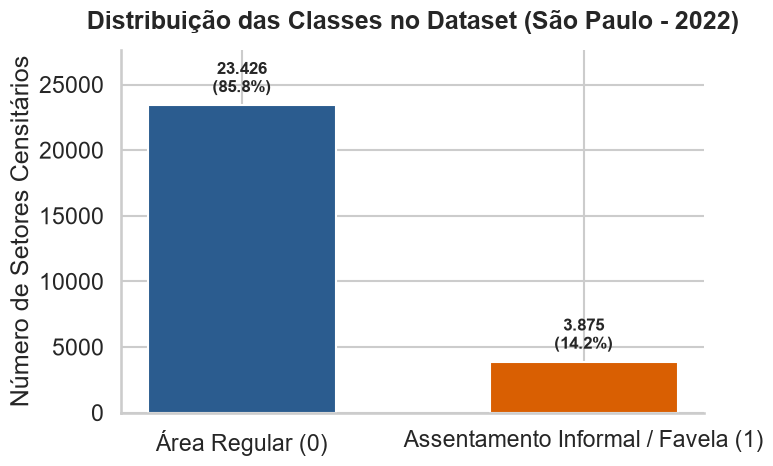

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
CORES = ["#2b5c8f", "#d95f02"]  

# Gráfico de Desbalanceamento de Classes (favela = 0 vs 1)
fig, ax = plt.subplots(figsize=(8, 5))
contagem = dataset["favela"].value_counts().sort_index()
labels = ["Área Regular (0)", "Assentamento Informal / Favela (1)"]
barras = ax.bar(labels, contagem.values, color=CORES, width=0.55)

for barra in barras:
    altura = barra.get_height()
    pct = (altura / len(dataset)) * 100
    ax.annotate(f"{altura:,}\n({pct:.1f}%)".replace(",", "."),
                xy=(barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 6), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold", fontsize=12)

ax.set_title("Distribuição das Classes no Dataset (São Paulo - 2022)", pad=15, fontweight="bold")
ax.set_ylabel("Número de Setores Censitários")
ax.set_ylim(0, contagem.max() * 1.18)
sns.despine()
plt.tight_layout()
plt.savefig(OUT / "grafico_1_classes.png", dpi=300)
plt.show()

### 2. Proporção de Sobreposição e Exemplos de Fronteira 
* **O que o gráfico mostra:** O histograma da variável `pct_favela` apenas para os setores censitários que possuem algum contato espacial com polígonos de FCUs (`pct_favela > 0`), destacando o limiar de corte em `50%`.
* **Análise dos resultados:** Observa-se uma concentração quase absoluta na faixa entre **95% e 100% de sobreposição** (próximo a `1.0`), com baixíssima ocorrência de casos intermediários nas faixas de transição. Isso demonstra que a malha censitária do IBGE de 2022 já delimita os setores respeitando os contornos das comunidades, o que reduz significativamente o ruído de fronteira (*borderline examples*) e valida a escolha do critério `THRESHOLD = 0.5` como uma regra segura para rotulagem automática (*Ground Truth*).

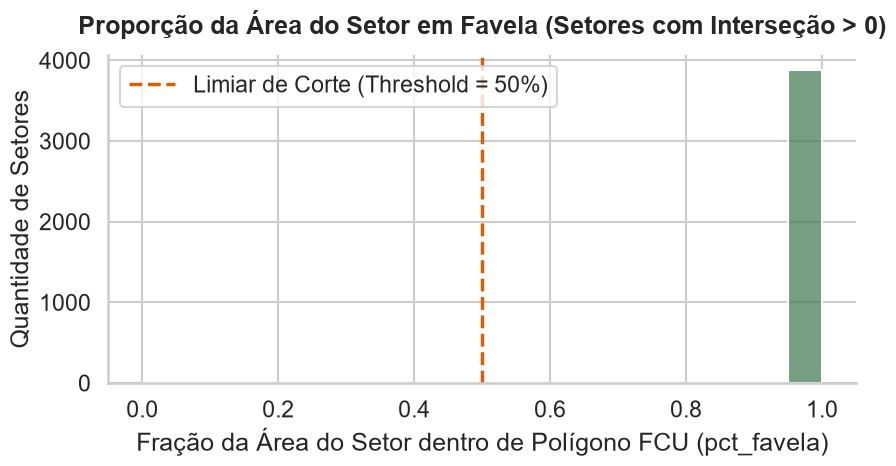

In [ ]:
# Histograma da Proporção de Área em Favela (Setores com interseção > 0)
fig, ax = plt.subplots(figsize=(9, 5))
com_intersecao = dataset[dataset["pct_favela"] > 0]["pct_favela"]

sns.histplot(com_intersecao, bins=20, color="#4a7c59", edgecolor="white", ax=ax)
ax.axvline(THRESHOLD, color="#d95f02", linestyle="--", linewidth=2.5,
           label=f"Limiar de Corte (Threshold = {THRESHOLD*100:.0f}%)")

ax.set_title("Proporção da Área do Setor em Favela (Setores com Interseção > 0)", pad=15, fontweight="bold")
ax.set_xlabel("Fração da Área do Setor dentro de Polígono FCU (pct_favela)")
ax.set_ylabel("Quantidade de Setores")
ax.legend()
sns.despine()
plt.tight_layout()
plt.savefig(OUT / "grafico_2_threshold_fronteira.png", dpi=300)
plt.show()

### 3. Comparativo Socioeconômico e de Infraestrutura
* **O que o gráfico mostra:** O contraste entre setores regulares e setores de favela em três dimensões: **renda média do responsável**, **densidade demográfica** e **indicadores de infraestrutura urbana** (rede de esgoto e vias estreitas).
* **Análise dos resultados:**
  * **Renda e Densidade:** Setores de favela apresentam mediana de rendimento significativamente inferior e menor dispersão de renda em comparação aos bairros regulares, ao mesmo tempo em que exibem densidades populacionais muito mais elevadas (refletindo lotes menores, verticalização informal e alta taxa de ocupação do solo).
  * **Infraestrutura e Traçado Viário:** Há uma queda perceptível na cobertura de esgotamento sanitário adequado (`pct_esgoto_adequado`) e um aumento expressivo na proporção de **vias exclusivas para pedestres, bicicletas e motos** (`pct_via_so_pedestre_moto`), indicador direto da presença de becos e vielas estreitas que caracterizam a morfologia irregular visível nas imagens de satélite.

C:\Users\davic\AppData\Local\Temp\ipykernel_21336\4158250701.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset_plot, x="Classe", y="renda_media_responsavel",
C:\Users\davic\AppData\Local\Temp\ipykernel_21336\4158250701.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset_plot, x="Classe", y="densidade_hab_km2",


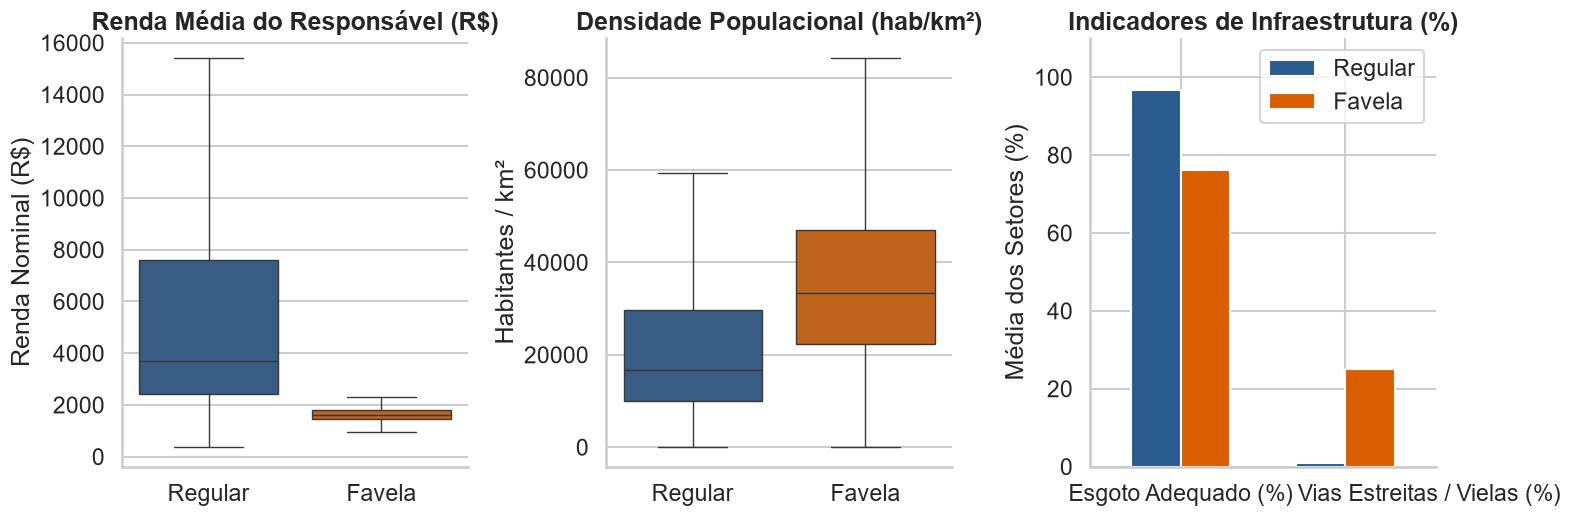

In [66]:
#Painel Comparativo: Renda, Densidade e Infraestrutura (Regular vs. Favela)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

dataset_plot = dataset.copy()
dataset_plot["Classe"] = dataset_plot["favela"].map({0: "Regular", 1: "Favela"})

# Subplot A: Renda Média do Responsável (sem outliers extremos para melhor visualização)
sns.boxplot(data=dataset_plot, x="Classe", y="renda_media_responsavel",
            palette=CORES, showfliers=False, ax=axes[0])
axes[0].set_title("Renda Média do Responsável (R$)", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Renda Nominal (R$)")

# Subplot B: Densidade Demográfica (hab/km²)
sns.boxplot(data=dataset_plot, x="Classe", y="densidade_hab_km2",
            palette=CORES, showfliers=False, ax=axes[1])
axes[1].set_title("Densidade Populacional (hab/km²)", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Habitantes / km²")

# Subplot C: Vias estreitas (só pedestres/motos) e Esgoto Adequado (Médias)
infra_medias = (
    dataset_plot.groupby("Classe")[["pct_esgoto_adequado", "pct_via_so_pedestre_moto"]]
    .mean()
    .reindex(["Regular", "Favela"]) * 100
)
infra_medias.columns = ["Esgoto Adequado (%)", "                            Vias Estreitas / Vielas (%)"]
infra_medias.T.plot(kind="bar", color=CORES, ax=axes[2], rot=0, width=0.6)
axes[2].set_title("Indicadores de Infraestrutura (%)", fontweight="bold")
axes[2].set_ylabel("Média dos Setores (%)")
axes[2].set_ylim(0, 110)
axes[2].legend(title="")

sns.despine()
plt.tight_layout()
plt.savefig(OUT / "grafico_3_comparativo_socioeconomico.png", dpi=300)
plt.show()

### 4. Distribuição Espacial dos Setores Rotulados
* **O que o gráfico mostra:** O mapeamento geoespacial dos 27.301 setores de São Paulo após a padronização para o sistema de coordenadas SIRGAS 2000 e cruzamento com os 96 distritos do GeoSampa.
* **Análise dos resultados:** O mapa evidencia a dispersão periférica e ao longo de eixos hídricos e áreas de mananciais dos 3.875 setores de assentamentos informais, confirmando a integridade geométrica das junções espaciais (`overlay` e `sjoin`) e servindo de guia geográfico para a etapa de extração das imagens de satélite via API.

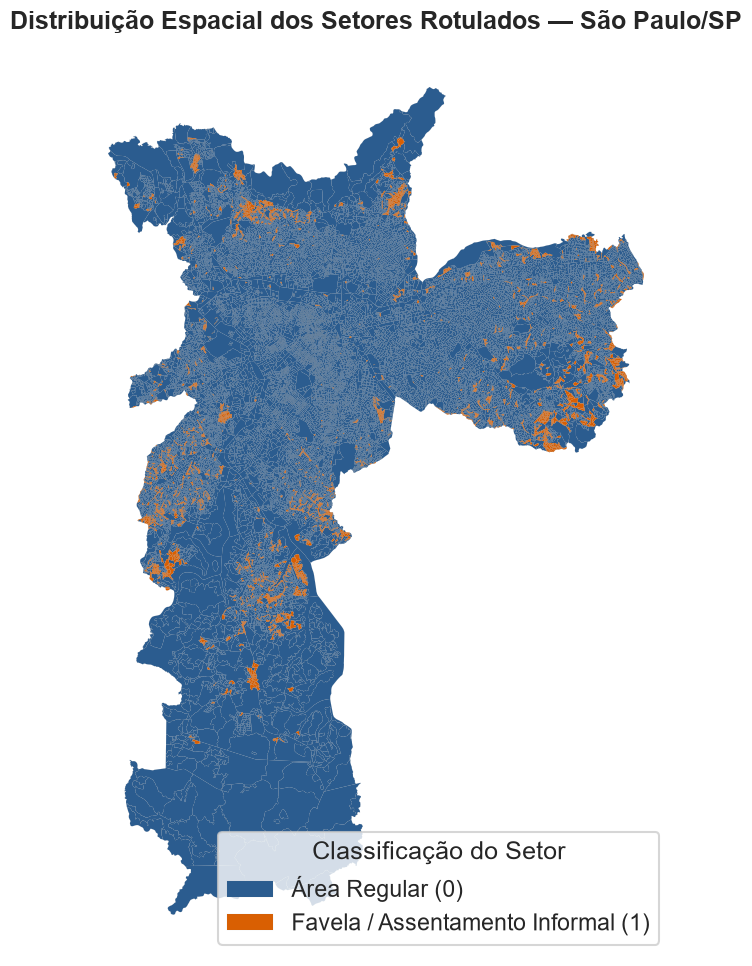

In [61]:
# 4. Mapa Espacial dos Setores Rotulados em São Paulo
fig, ax = plt.subplots(figsize=(9, 10))
dataset_geo.plot(column="favela", categorical=True, legend=True,
                 cmap=plt.cm.colors.ListedColormap(CORES),
                 linewidth=0.05, edgecolor="gray", ax=ax,
                 legend_kwds={"labels": ["Área Regular (0)", "Favela / Assentamento Informal (1)"],
                              "loc": "lower right", "title": "Classificação do Setor"})

ax.set_title("Distribuição Espacial dos Setores Rotulados — São Paulo/SP", pad=12, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.savefig(OUT / "grafico_4_mapa_sao_paulo.png", dpi=300)
plt.show()

### 5. Morfologia Construtiva, Entorno e Perfil Demográfico 

* **O que o gráfico mostra:** A comparação das médias percentuais entre **Áreas Regulares (`0`)** e **Assentamentos Informais / Favelas (`1`)** dividida em dois painéis: características físicas do ambiente construído (tipologia habitacional, arborização e calçamento) e perfil sociodemográfico dos moradores (raça/cor e faixa etária).
* **Análise dos resultados:**
  * **Morfologia Construtiva e Entorno (Painel Esquerdo):** Nos assentamentos informais, **96,1%** dos domicílios são casas (contra **56,2%** nas áreas regulares) e apenas **0,4%** são apartamentos (contra **41,3%** nas áreas regulares) — os cerca de 3,5% restantes correspondem às demais tipologias do IBGE, como casas de vila/condomínio, cortiços e estruturas inacabadas ou degradadas. Além disso, há uma queda acentuada na presença de **arborização** (**29,3%** contra **75,0%**) e **calçadas** (**54,6%** contra **96,3%**), evidenciando a alta taxa de ocupação do solo e a ausência de espaços livres permeáveis, atributos diretamente detectáveis na textura das imagens de satélite.
  * **Perfil Demográfico e Considerações Éticas (Painel Direito):** A população **preta e parda** representa em média **66,3%** dos moradores nos setores de favela (contra **36,4%** nas áreas regulares), acompanhada por uma proporção maior de **crianças e jovens de 0 a 14 anos** (**23,2%** contra **15,0%**) e menor de **idosos** (**8,9%** contra **19,9%**). Esse recorte reforça a necessidade de rigor ético no uso do dataset, garantindo que os modelos desenvolvidos sirvam ao planejamento urbano inclusivo e à mitigação de vulnerabilidades, evitando vieses algorítmicos ou estigmatização territorial.

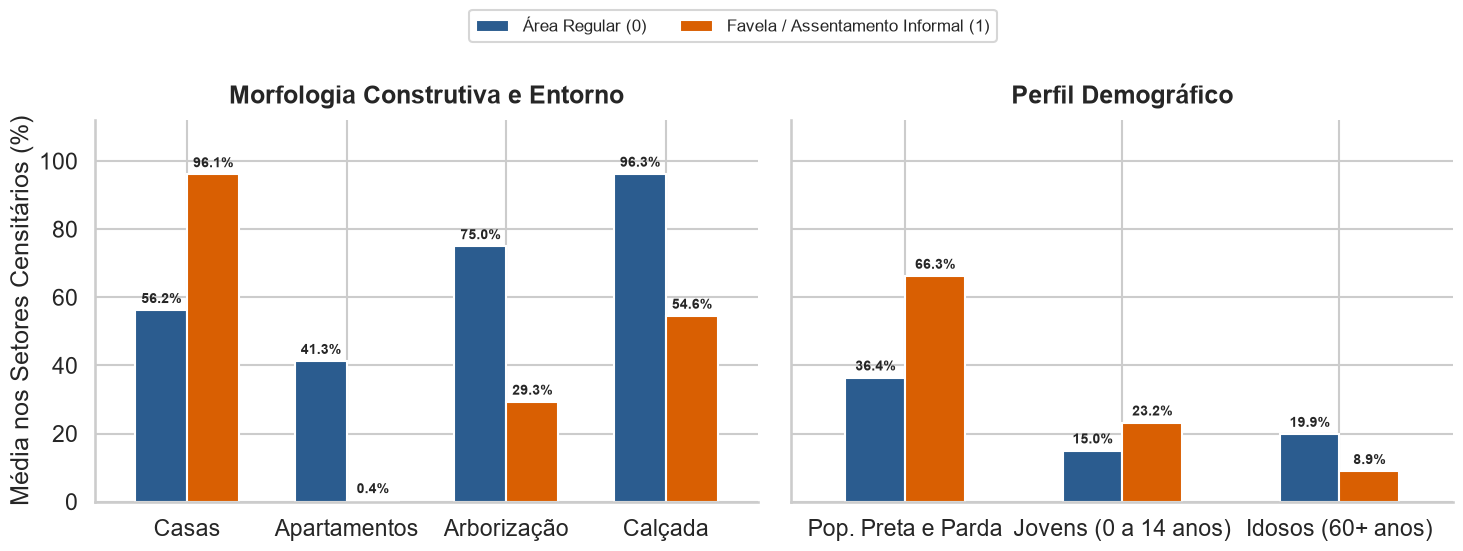

In [ ]:
#(Morfologia/Entorno vs. Perfil Demográfico)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
CORES = ["#2b5c8f", "#d95f02"]

# Morfologia Construtiva e Entorno Visual
cols_fisicas = ["pct_casa", "pct_apartamento", "pct_arborizacao", "pct_calcada"]
df_fisico = dataset.groupby("favela")[cols_fisicas].mean().reindex([0, 1]) * 100
df_fisico.index = ["Área Regular (0)", "Favela / Assentamento Informal (1)"]
df_fisico.columns = ["Casas", "Apartamentos", "Arborização", "Calçada"]

df_fisico.T.plot(kind="bar", color=CORES, ax=axes[0], rot=0, width=0.65, legend=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10, fontweight="bold")

axes[0].set_title("Morfologia Construtiva e Entorno", fontweight="bold", pad=12)
axes[0].set_ylabel("Média nos Setores Censitários (%)")
axes[0].set_ylim(0, 112)

#Perfil Demográfico
cols_demo = ["pct_preta_parda", "pct_0a14", "pct_60mais"]
df_demo = dataset.groupby("favela")[cols_demo].mean().reindex([0, 1]) * 100
df_demo.index = ["Área Regular (0)", "Favela / Assentamento Informal (1)"]
df_demo.columns = ["Pop. Preta e Parda", "Jovens (0 a 14 anos)", "Idosos (60+ anos)"]

df_demo.T.plot(kind="bar", color=CORES, ax=axes[1], rot=0, width=0.55, legend=False)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10, fontweight="bold")

axes[1].set_title("Perfil Demográfico", fontweight="bold", pad=12)
axes[1].set_ylim(0, 112)


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, frameon=True, fontsize=12)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(OUT / "grafico_6_morfologia_etica.png", dpi=300)
plt.show()

In [ ]:
df_fisico.columns = ["Casas", "Apartamentos", "Arborização", "Calçada"]

df_fisico.T.plot(kind="bar", color=CORES, ax=axes[0], rot=0, width=0.65, legend=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10, fontweight="bold")

axes[0].set_title("Morfologia Construtiva e Entorno", fontweight="bold", pad=12)
axes[0].set_ylabel("Média nos Setores Censitários (%)")
axes[0].set_ylim(0, 112)

#Perfil Demográfico
cols_demo = ["pct_preta_parda", "pct_0a14", "pct_60mais"]
df_demo = dataset.groupby("favela")[cols_demo].mean().reindex([0, 1]) * 100
df_demo.index = ["Área Regular (0)", "Favela / Assentamento Informal (1)"]
df_demo.columns = ["Pop. Preta e Parda", "Jovens (0 a 14 anos)", "Idosos (60+ anos)"]

df_demo.T.plot(kind="bar", color=CORES, ax=axes[1], rot=0, width=0.55, legend=False)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10, fontweight="bold")

axes[1].set_title("Perfil Demográfico", fontweight="bold", pad=12)
axes[1].set_ylim(0, 112)

# Legenda única centralizada no topo, fora da área das barras
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, frameon=True, fontsize=12)

sns.despine()
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(OUT / "grafico_6_morfologia_etica.png", dpi=300)
plt.show()

### 6. Auditoria de Valores Faltantes (`NaN`) por Origem 
* **O que o gráfico mostra:** O volume e o percentual de valores ausentes em cada coluna do dataset consolidado, agrupados pela causa técnica de sua ocorrência.
* **Análise dos resultados:** A investigação comprova que os valores ausentes não decorrem de falhas de integração, mas de características estruturais e metodológicas das fontes oficiais:
  1. **Não aplicável (`code_favela` e `name_favela` — 23.426 nulos / 85,8%):** Ocorre exclusivamente nos setores regulares, onde não há código ou nome de comunidade associado.
  2. **Escopo da pesquisa de entorno (1.019 nulos / 3,7%):** As variáveis urbanísticas (`pct_via_pavimentada`, `pct_bueiro`, `pct_calcada`, etc.) são pesquisadas pelo IBGE apenas em setores urbanos com domicílios, ficando ausentes em áreas rurais ou não edificadas.
  3. **Sigilo estatístico ou ausência de moradores (622 a 636 nulos / ~2,3%):** Setores sem população residente ou com poucos domicílios em que o IBGE omite os valores com `"X"` para preservar o sigilo dos informantes.
  4. **Inconsistências cartográficas e massas d'água (2 a 10 nulos / <0,1%):** Pequenas divergências de contorno entre as malhas do IBGE e da Prefeitura (`distrito_prefeitura`: 2 casos) e setores correspondentes a represas/corpos hídricos (`zone`: 10 casos).

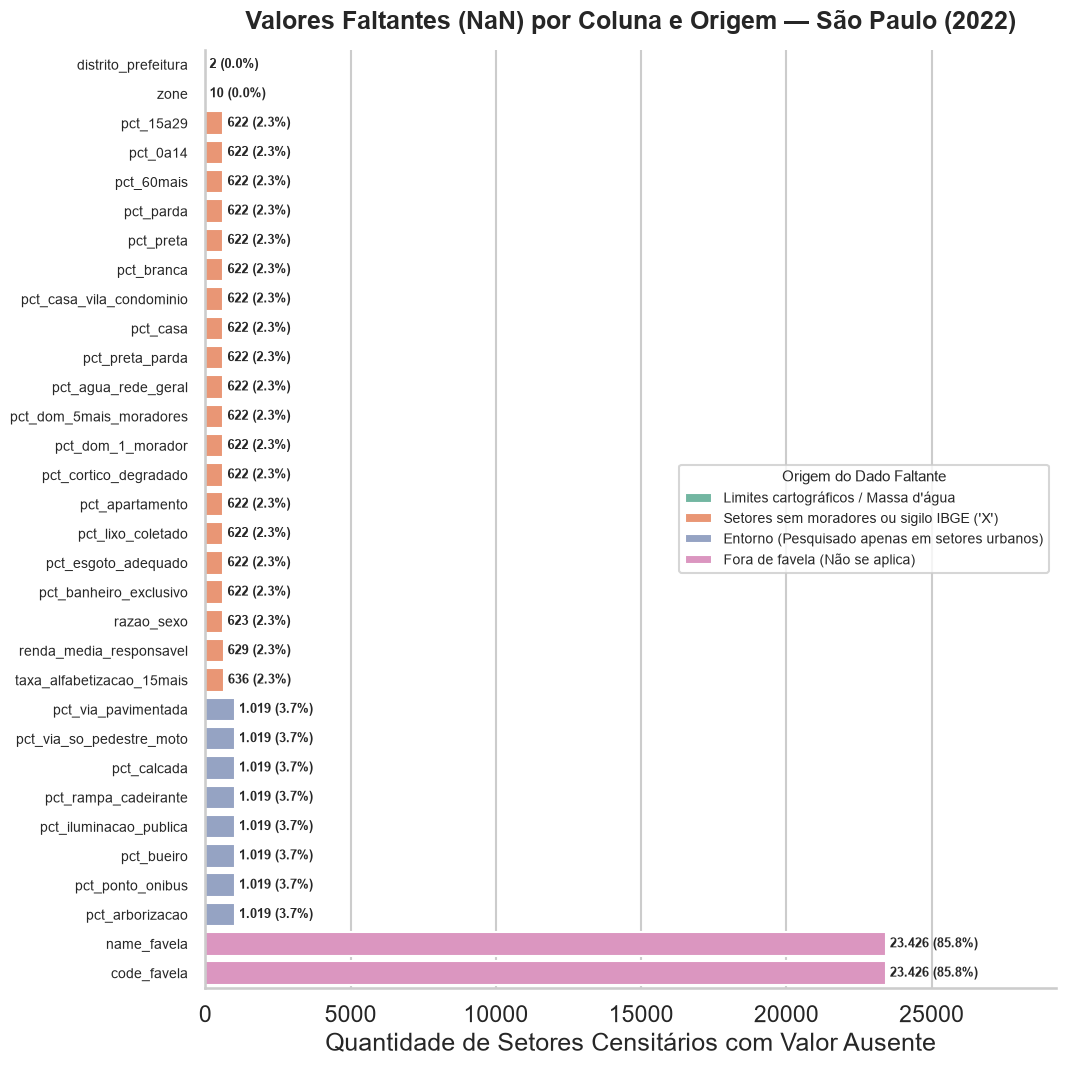

In [ ]:
#Visualização dos Dados Faltantes (NaN) por Coluna e Origem
nulos = dataset.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=True)

# Mapeia a origem/causa de cada grupo de nulos (conforme auditoria do notebook)
def classificar_origem(col):
    if col in ["code_favela", "name_favela"]:
        return "Fora de favela (Não se aplica)"
    elif col.startswith("pct_via") or col in ["pct_iluminacao_publica", "pct_bueiro", "pct_calcada",
                                               "pct_rampa_cadeirante", "pct_ponto_onibus", "pct_arborizacao"]:
        return "Entorno (Pesquisado apenas em setores urbanos)"
    elif col in ["zone", "distrito_prefeitura"]:
        return "Limites cartográficos / Massa d'água"
    else:
        return "Setores sem moradores ou sigilo IBGE ('X')"

origens = [classificar_origem(col) for col in nulos.index]
df_nulos = pd.DataFrame({"Coluna": nulos.index, "Nulos": nulos.values, "Origem": origens})

fig, ax = plt.subplots(figsize=(11, 11))
sns.barplot(data=df_nulos, x="Nulos", y="Coluna", hue="Origem", dodge=False, palette="Set2", ax=ax)

total_setores = len(dataset)
for bar in ax.patches:
    largura = bar.get_width()
    if largura > 0:
        pct = (largura / total_setores) * 100
        ax.annotate(f" {int(largura):,} ({pct:.1f}%)".replace(",", "."),
                    xy=(largura, bar.get_y() + bar.get_height() / 2),
                    va="center", ha="left", fontsize=9, fontweight="bold")

ax.set_title("Valores Faltantes (NaN) por Coluna e Origem — São Paulo (2022)", pad=15, fontweight="bold")
ax.set_xlabel("Quantidade de Setores Censitários com Valor Ausente")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=10)
ax.set_xlim(0, nulos.max() * 1.25)

# Move a legenda para o espaço livre no centro-direita, sem cobrir as barras de 85.8%
ax.legend(title="Origem do Dado Faltante", loc="center right", frameon=True, fontsize=10, title_fontsize=11)
sns.despine()
plt.tight_layout()
plt.savefig(OUT / "grafico_5_dados_faltantes.png", dpi=300)
plt.show()